# <span style="color: #a855f7">Regression model evaluation</span>

<span style="color: #a855f7">прогноз ціни авто, train/test без витоку даних, базова й поліноміальна моделі, залишки, залежність від split і K-Fold cross-validation</span>

In [1]:
from html import escape
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

DATA_URL = "https://raw.githubusercontent.com/arib168/data/main/CarPrice_Assignment.csv"
TEST_SIZE = 0.2
RANDOM_STATE = 42
PURPLE = "#a855f7"
PINK = "#f472b6"
BLUE = "#60a5fa"
YELLOW = "#facc15"


def colorize(value, *, index=True):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        table = value.to_frame() if isinstance(value, pd.Series) else value
        html = table.to_html(border=0, index=index).replace(
            '<table ', '<table style="color: #a855f7; margin-left: 0; margin-right: auto; border-collapse: collapse" '
        )
        for tag in ("th", "td"):
            html = html.replace(
                f"<{tag}>",
                f'<{tag} style="padding: 6px 12px; border-bottom: 1px solid #746a80">',
            )
        display(HTML(html))
    else:
        display(HTML(f'<pre style="color: #a855f7; background: transparent">{escape(str(value))}</pre>'))


def regression_metrics(actual, predicted):
    return {
        "R²": r2_score(actual, predicted),
        "MAE (USD)": mean_absolute_error(actual, predicted),
        "RMSE (USD)": root_mean_squared_error(actual, predicted),
    }


def make_regression_pipeline(degree=1):
    steps = []
    if degree > 1:
        steps.append(("polynomial", PolynomialFeatures(degree=degree, include_bias=False)))
    steps.extend([("scaler", StandardScaler()), ("regression", LinearRegression())])
    return Pipeline(steps)


plt.style.use("dark_background")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "figure.facecolor": "#111116",
    "axes.facecolor": "#111116",
    "axes.edgecolor": "#746a80",
    "axes.labelcolor": "#e9d5ff",
    "axes.titlecolor": "#e9d5ff",
    "axes.titlesize": 13,
    "text.color": "#e9d5ff",
    "xtick.color": "#d8c8ed",
    "ytick.color": "#d8c8ed",
    "grid.color": "#746a80",
    "grid.alpha": 0.25,
    "lines.linewidth": 2,
    "font.size": 10,
})

## <span style="color: #a855f7">Car data and selected features</span>

<span style="color: #a855f7">205 авто, дані читаються за посиланням з тз, для запуску потрібен інтернет, X містить рівно 5 заданих числових ознак, price - ціль у USD, перевіряються схема, пропуски і скінченність значень</span>

In [2]:
with urlopen(DATA_URL, timeout=30) as response:
    df = pd.read_csv(response)
features = ["enginesize", "horsepower", "curbweight", "highwaympg", "carlength"]
required_columns = features + ["price"]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")
if len(df) != 205:
    raise ValueError(f"Expected 205 cars, received {len(df)}")
selected_data = df[required_columns].apply(pd.to_numeric, errors="raise")
if not np.isfinite(selected_data.to_numpy(dtype=float)).all():
    raise ValueError("Selected features and price must contain only finite values")
if selected_data["price"].le(0).any():
    raise ValueError("Car prices must be positive")
X = selected_data[features].copy()
y = selected_data["price"].copy()
colorize(f"Dataset shape: {df.shape} | X shape: {X.shape} | y shape: {y.shape}")
colorize("First 5 selected rows")
colorize(selected_data.head())
colorize("Missing values in selected columns")
colorize(selected_data.isna().sum().rename("missing"))

,enginesize,horsepower,curbweight,highwaympg,carlength,price
0,130,111,2548,27,168.8,13495.0
1,130,111,2548,27,168.8,16500.0
2,152,154,2823,26,171.2,16500.0
3,109,102,2337,30,176.6,13950.0
4,136,115,2824,22,176.6,17450.0


,missing
enginesize,0
horsepower,0
curbweight,0
highwaympg,0
carlength,0
price,0


## <span style="color: #a855f7">Train/test split and scaling</span>

<span style="color: #a855f7">split 80/20 з random_state = 42 виконується до масштабування, fit_transform використовується лише для X_train, для X_test - transform, price не масштабується, тому помилки залишаються в USD</span>

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE,
)
scaler = StandardScaler()
X_train_scaled = np.asarray(scaler.fit_transform(X_train), dtype=float)
X_test_scaled = np.asarray(scaler.transform(X_test), dtype=float)
if not X_train.index.intersection(X_test.index).empty:
    raise ValueError("Train and test rows must not overlap")
np.testing.assert_allclose(scaler.mean_, X_train.mean().to_numpy())
np.testing.assert_allclose(X_train_scaled.mean(axis=0), 0, atol=1e-12)
np.testing.assert_allclose(X_train_scaled.std(axis=0), 1, atol=1e-12)
colorize(pd.DataFrame({
    "split": ["train", "test"],
    "rows": [len(X_train), len(X_test)],
    "features": [X_train.shape[1], X_test.shape[1]],
}), index=False)
colorize("Scaled train statistics")
colorize(pd.DataFrame({
    "feature": features,
    "mean": X_train_scaled.mean(axis=0),
    "std (ddof=0)": X_train_scaled.std(axis=0),
}).round(10), index=False)

split,rows,features
train,164,5
test,41,5


feature,mean,std (ddof=0)
enginesize,-0.0,1.0
horsepower,-0.0,1.0
curbweight,-0.0,1.0
highwaympg,-0.0,1.0
carlength,0.0,1.0


## <span style="color: #a855f7">Baseline linear regression</span>

<span style="color: #a855f7">навчання LinearRegression на масштабованому train, R², MAE і RMSE для обох вибірок, R² безрозмірний і може бути від'ємним, MAE та RMSE вимірюються в USD</span>

In [4]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)
y_train_pred = np.asarray(model.predict(X_train_scaled), dtype=float)
y_test_pred = np.asarray(model.predict(X_test_scaled), dtype=float)
baseline_metrics = pd.DataFrame([
    {"split": "train", **regression_metrics(y_train, y_train_pred)},
    {"split": "test", **regression_metrics(y_test, y_test_pred)},
])
colorize(baseline_metrics.round({"R²": 4, "MAE (USD)": 2, "RMSE (USD)": 2}), index=False)

split,R²,MAE (USD),RMSE (USD)
train,0.8114,2382.59,3353.57
test,0.8160,2789.16,3811.27


## <span style="color: #a855f7">Standardized coefficients</span>

<span style="color: #a855f7">коефіцієнти відсортовані за абсолютною величиною, додатний коефіцієнт показує зростання прогнозу при збільшенні ознаки на 1 train std за фіксованих інших ознак, взаємопов’язані ознаки впливають на інтерпретацію, це не доказ причинності</span>

In [5]:
coefficients = pd.DataFrame({
    "feature": features,
    "coefficient (USD per std)": np.asarray(model.coef_, dtype=float),
})
coefficients["absolute coefficient"] = coefficients["coefficient (USD per std)"].abs()
coefficients = coefficients.sort_values("absolute coefficient", ascending=False).reset_index(drop=True)
strongest_positive = coefficients.loc[coefficients["coefficient (USD per std)"].idxmax()]
colorize(coefficients.round(2), index=False)
colorize(f"Largest positive standardized coefficient: {strongest_positive['feature']} ({strongest_positive['coefficient (USD per std)']:.2f} USD per std)")
colorize(f"Intercept: {float(model.intercept_):.2f} USD at train-average feature values")

feature,coefficient (USD per std),absolute coefficient
enginesize,3246.25,3246.25
horsepower,2167.46,2167.46
curbweight,1617.46,1617.46
carlength,395.72,395.72
highwaympg,-146.66,146.66


## <span style="color: #a855f7">Test residuals</span>

<span style="color: #a855f7">по X - передбачена ціна, по Y - actual мінус predicted, додатні залишки означають недооцінку ціни, від'ємні - переоцінку, нульова лінія показує точний прогноз</span>

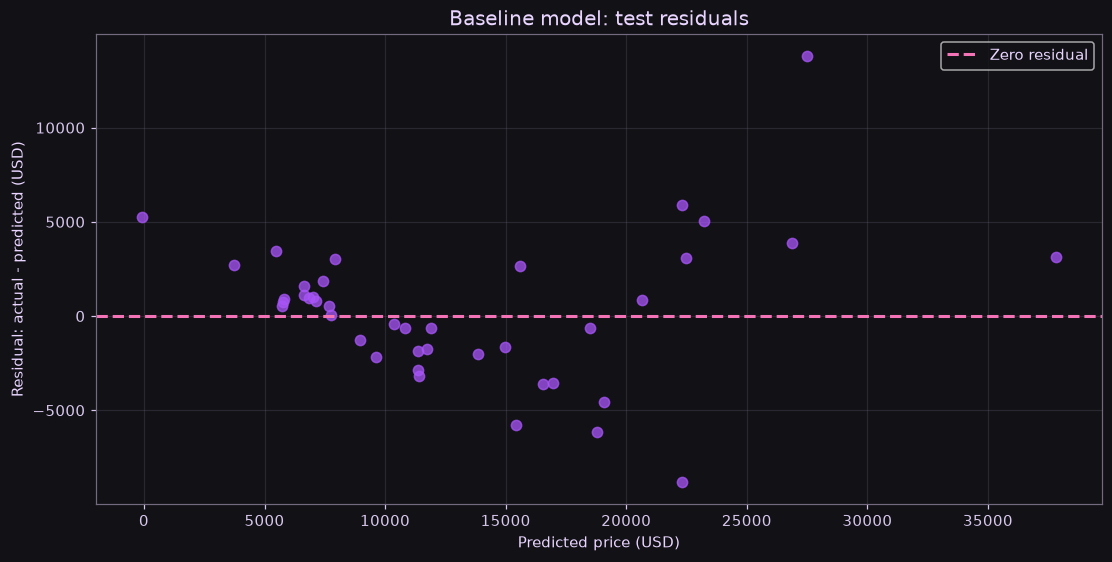

,actual (USD),predicted (USD),residual (USD)
15,30760.00,26865.18,3894.82
9,17859.17,18484.42,-625.25
100,9549.00,11382.48,-1833.48
132,11850.00,13864.61,-2014.61
68,28248.00,23226.40,5021.60


In [6]:
test_residuals = y_test.to_numpy() - y_test_pred
fig, ax = plt.subplots(layout="constrained")
ax.scatter(y_test_pred, test_residuals, color=PURPLE, s=45, alpha=0.75)
ax.axhline(0, color=PINK, linestyle="--", label="Zero residual")
ax.set(title="Baseline model: test residuals", xlabel="Predicted price (USD)", ylabel="Residual: actual - predicted (USD)")
ax.legend()
ax.grid()
ax.set_axisbelow(True)
plt.show()
colorize(pd.DataFrame({
    "actual (USD)": y_test.to_numpy(),
    "predicted (USD)": y_test_pred,
    "residual (USD)": test_residuals,
}, index=y_test.index).head().round(2))

## <span style="color: #a855f7">Polynomial regression and overfitting</span>

<span style="color: #a855f7">PolynomialFeatures degree=3, include_bias=False, далі StandardScaler і LinearRegression, всі fit виконуються лише на train, порівнюється розрив train/test R², underfitting означав би низьку якість на обох вибірках, сам по собі поліном не гарантує перенавчання - висновок робиться за результатами</span>

split,R²,MAE (USD),RMSE (USD)
train,0.9474,1366.88,1771.9
test,0.7881,2684.27,4090.3


model,train R²,test R²,train-test gap
Linear,0.8114,0.8160,-0.0046
Polynomial degree 3,0.9474,0.7881,0.1593


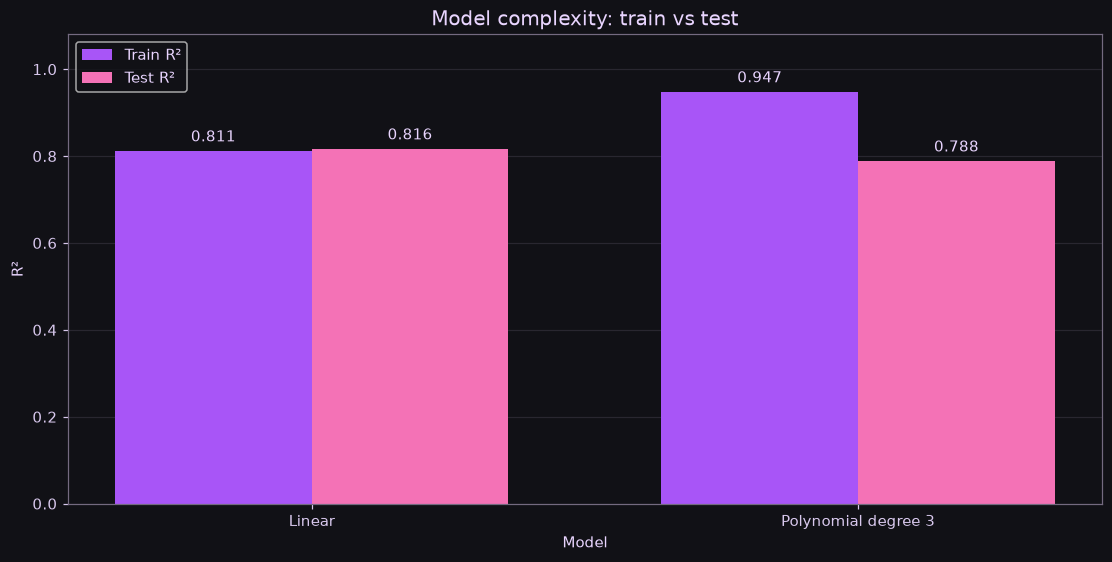

In [7]:
poly = PolynomialFeatures(degree=3, include_bias=False)
X_train_poly = np.asarray(poly.fit_transform(X_train), dtype=float)
X_test_poly = np.asarray(poly.transform(X_test), dtype=float)
scaler_poly = StandardScaler()
X_train_poly_scaled = np.asarray(scaler_poly.fit_transform(X_train_poly), dtype=float)
X_test_poly_scaled = np.asarray(scaler_poly.transform(X_test_poly), dtype=float)
poly_lr = LinearRegression()
poly_lr.fit(X_train_poly_scaled, y_train)
poly_train_pred = np.asarray(poly_lr.predict(X_train_poly_scaled), dtype=float)
poly_test_pred = np.asarray(poly_lr.predict(X_test_poly_scaled), dtype=float)
polynomial_metrics = pd.DataFrame([
    {"split": "train", **regression_metrics(y_train, poly_train_pred)},
    {"split": "test", **regression_metrics(y_test, poly_test_pred)},
])
colorize(f"Original features: {X_train.shape[1]} | polynomial features: {X_train_poly.shape[1]}")
colorize(polynomial_metrics.round({"R²": 4, "MAE (USD)": 2, "RMSE (USD)": 2}), index=False)
complexity_summary = pd.DataFrame({
    "model": ["Linear", "Polynomial degree 3"],
    "train R²": [baseline_metrics.loc[0, "R²"], polynomial_metrics.loc[0, "R²"]],
    "test R²": [baseline_metrics.loc[1, "R²"], polynomial_metrics.loc[1, "R²"]],
})
complexity_summary["train-test gap"] = complexity_summary["train R²"] - complexity_summary["test R²"]
colorize(complexity_summary.round(4), index=False)
positions = np.arange(len(complexity_summary), dtype=float)
fig, ax = plt.subplots(layout="constrained")
train_bars = ax.bar(positions - 0.18, complexity_summary["train R²"].to_numpy(), width=0.36, color=PURPLE, label="Train R²")
test_bars = ax.bar(positions + 0.18, complexity_summary["test R²"].to_numpy(), width=0.36, color=PINK, label="Test R²")
ax.bar_label(train_bars, fmt="%.3f", padding=4)
ax.bar_label(test_bars, fmt="%.3f", padding=4)
ax.set_xticks(positions, complexity_summary["model"].tolist())
ax.set(title="Model complexity: train vs test", xlabel="Model", ylabel="R²", ylim=(0, 1.08))
ax.legend(loc="upper left")
ax.grid(axis="y")
ax.set_axisbelow(True)
plt.show()

<span style="color: #a855f7">поліном має вищий train R², але нижчий test R² і більший розрив між ними, це ознака перенавчання на цьому split, висока train-оцінка не гарантує кращого прогнозу нових авто</span>

## <span style="color: #a855f7">Split sensitivity</span>

<span style="color: #a855f7">15 окремих split з random_state від 1 до 15, щоразу створюється новий pipeline зі scaler і LinearRegression, виводяться всі test R², min, max, avg і range</span>

random_state,test R²
1,0.7790
2,0.6509
3,0.8422
4,0.7450
5,0.8844
6,0.7822
7,0.7552
8,0.6934
9,0.8248
10,0.5744


min R²,max R²,avg R²,range
0.5744,0.8912,0.7565,0.3169


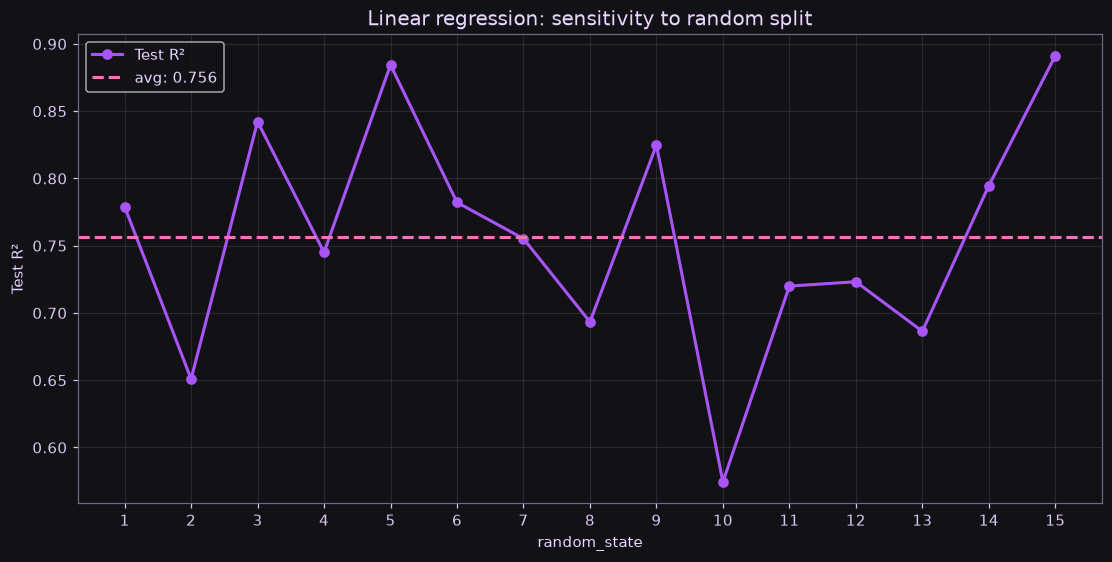

In [8]:
split_results = []
for random_state in range(1, 16):
    split_X_train, split_X_test, split_y_train, split_y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=random_state,
    )
    split_model = make_regression_pipeline()
    split_model.fit(split_X_train, split_y_train)
    split_results.append({
        "random_state": random_state,
        "test R²": split_model.score(split_X_test, split_y_test),
    })
split_results = pd.DataFrame(split_results)
split_scores = split_results["test R²"].to_numpy()
split_summary = pd.DataFrame({
    "min R²": [split_scores.min()],
    "max R²": [split_scores.max()],
    "avg R²": [split_scores.mean()],
    "range": [np.ptp(split_scores)],
})
colorize(split_results.round(4), index=False)
colorize("Split score summary")
colorize(split_summary.round(4), index=False)
fig, ax = plt.subplots(layout="constrained")
ax.plot(split_results["random_state"].to_numpy(), split_scores, color=PURPLE, marker="o", label="Test R²")
ax.axhline(split_scores.mean(), color=PINK, linestyle="--", label=f"avg: {split_scores.mean():.3f}")
ax.set(title="Linear regression: sensitivity to random split", xlabel="random_state", ylabel="Test R²")
ax.set_xticks(list(range(1, 16)))
ax.legend()
ax.grid()
ax.set_axisbelow(True)
plt.show()

## <span style="color: #a855f7">5-Fold and 10-Fold cross-validation</span>

<span style="color: #a855f7">CV використовує весь X за умовою ТЗ, але масштабування навчається всередині кожного fold через Pipeline, попередній fit scaler на всьому X не виконується, KFold має shuffle=True і random_state=42, однакові fold використовуються для двох моделей</span>

<span style="color: #a855f7">основне порівняння моделей - 5-Fold, 10-Fold перевіряє стійкість висновку, std описує розкид оцінок між fold і не є довірчим інтервалом, CV на всьому наборі повторно використовує рядки початкового test, тому її не називаємо новою незалежною фінальною test-перевіркою</span>

In [9]:
cv_models = {
    "Linear": make_regression_pipeline(),
    "Polynomial degree 3": make_regression_pipeline(degree=3),
}
cv_results = []
cv_scores = {}
for folds in (5, 10):
    splitter = KFold(n_splits=folds, shuffle=True, random_state=RANDOM_STATE)
    for model_name, estimator in cv_models.items():
        scores = np.asarray(cross_val_score(
            estimator, X, y, cv=splitter, scoring="r2", error_score="raise",
        ), dtype=float)
        if not np.isfinite(scores).all():
            raise ValueError("Cross-validation produced non-finite scores")
        cv_scores[(model_name, folds)] = scores
        cv_results.append({
            "model": model_name,
            "folds": folds,
            "avg R²": scores.mean(),
            "std R²": scores.std(ddof=0),
            "min R²": scores.min(),
            "max R²": scores.max(),
        })
    fold_table = pd.DataFrame({
        "fold": np.arange(1, folds + 1),
        **{name: cv_scores[(name, folds)] for name in cv_models},
    })
    colorize(f"{folds}-Fold validation scores")
    colorize(fold_table.round(4), index=False)
cv_summary = pd.DataFrame(cv_results)
cv_summary["avg ± std"] = [f"{avg:.4f} ± {std:.4f}" for avg, std in zip(cv_summary["avg R²"], cv_summary["std R²"], strict=True)]
colorize("Cross-validation summary")
colorize(cv_summary[["model", "folds", "avg ± std", "min R²", "max R²"]].round(4), index=False)

fold,Linear,Polynomial degree 3
1,0.8160,0.7881
2,0.7177,0.6490
3,0.7903,0.7749
4,0.8303,-0.3423
5,0.7896,-149.5354


fold,Linear,Polynomial degree 3
1,0.9104,-0.0937
2,0.7086,0.8091
3,0.6702,0.7527
4,0.8465,0.4143
5,0.7719,0.8070
6,0.7659,0.8221
7,0.8120,0.7915
8,0.7984,0.2516
9,0.8650,-310.4108
10,0.7752,-1.2098


model,folds,avg ± std,min R²,max R²
Linear,5,0.7888 ± 0.0388,0.7177,0.8303
Polynomial degree 3,5,-29.5331 ± 60.0026,-149.5354,0.7881
Linear,10,0.7924 ± 0.0678,0.6702,0.9104
Polynomial degree 3,10,-30.7066 ± 93.2367,-310.4108,0.8221


## <span style="color: #a855f7">Cross-validation stability</span>

<span style="color: #a855f7">на графіках показані всі fold, симетрична логарифмічна шкала з лінійною областю від -1 до 1 зберігає видимими і додатні, і великі від'ємні R², від'ємний R² означає гіршу оцінку, ніж постійний прогноз середнього validation-цілі</span>

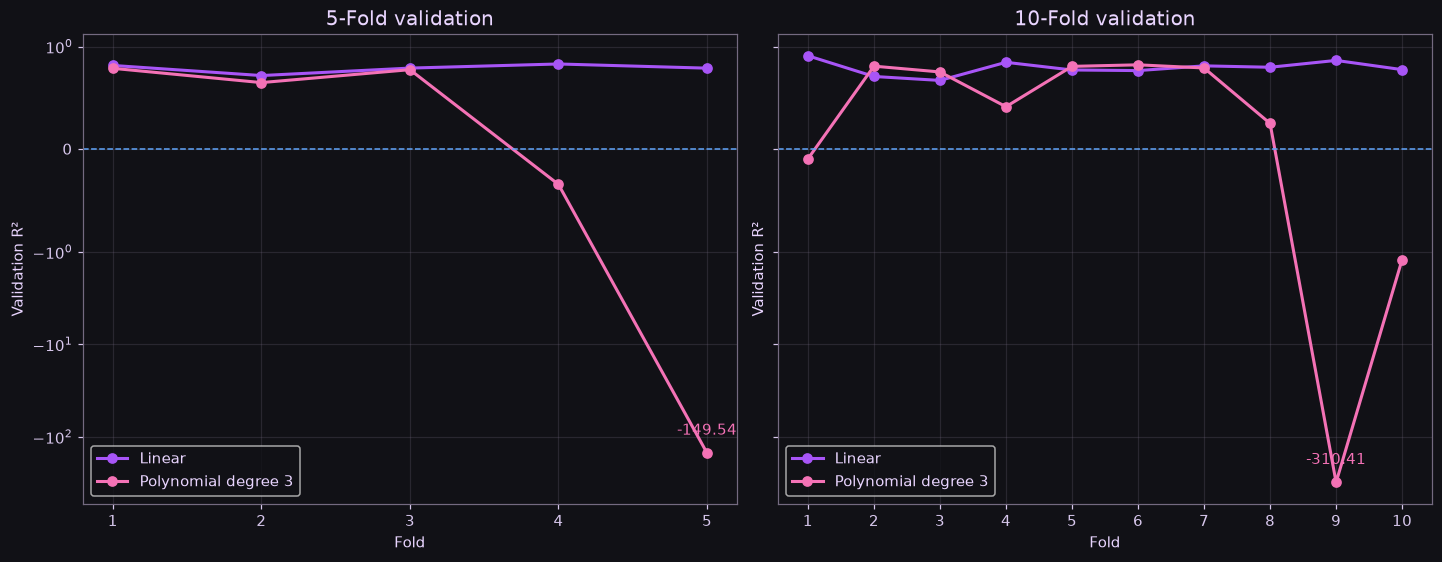

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained", sharey=True)
for ax, folds in zip(axes, (5, 10), strict=True):
    fold_axis = np.arange(1, folds + 1)
    for model_name, color in [("Linear", PURPLE), ("Polynomial degree 3", PINK)]:
        scores = cv_scores[(model_name, folds)]
        ax.plot(fold_axis, scores, color=color, marker="o", label=model_name)
        if scores.min() < -1:
            worst = int(np.argmin(scores))
            ax.annotate(f"{scores[worst]:.2f}", (fold_axis[worst], scores[worst]), xytext=(0, 12), textcoords="offset points", ha="center", color=color)
    ax.axhline(0, color=BLUE, linestyle="--", linewidth=1)
    ax.set(title=f"{folds}-Fold validation", xlabel="Fold", ylabel="Validation R²", yscale="symlog")
    ax.set_yscale("symlog", linthresh=1)
    ax.set_xticks(fold_axis)
    ax.legend(loc="lower left")
    ax.grid()
    ax.set_axisbelow(True)
plt.show()
selection_scores = cv_summary.loc[cv_summary["folds"] == 5].sort_values("avg R²", ascending=False)
preferred_model = selection_scores.iloc[0]["model"]
colorize(f"Preferred model by 5-Fold avg R²: {preferred_model}")

<span style="color: #a855f7">лінійна модель має кращий avg R² і менший розкид, поліном 3-го степеня дуже чутливий до окремих fold, великі від'ємні оцінки показують нестійкість узагальнення, додаткові поліноміальні ознаки не дали надійного покращення, в межах порівняних моделей обирається LinearRegression, для подальшого підбору потрібні окремий validation-процес і незалежна фінальна test-вибірка</span>